In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../Data/processed/merged.csv", parse_dates=["date"])
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])   # should print nothing (no missing values)

Matplotlib is building the font cache; this may take a moment.


(3000888, 28)
Series([], dtype: int64)


In [2]:
row = df[(df["city"] == "Quito") & (df["date"] == "2015-06-15")].iloc[0]
w_quito = pd.read_csv("../Data/raw/weather/Quito.csv", parse_dates=["date"])
print(row[["temperature_2m_mean", "precipitation_sum"]])
print(w_quito[w_quito["date"] == "2015-06-15"])   # values should match

temperature_2m_mean    12.9
precipitation_sum       1.8
Name: 1591326, dtype: object
          date   city  temperature_2m_max  temperature_2m_min  \
895 2015-06-15  Quito                18.8                 7.7   

     temperature_2m_mean  precipitation_sum  rain_sum  
895                 12.9                1.8       1.8  


In [3]:
print(df.groupby("city").size())
print(df.groupby("is_holiday")["sales"].mean())
print(df.groupby("is_payday")["sales"].mean())
print(df.groupby("is_rainy")["sales"].mean())

city
Ambato            111144
Babahoyo           55572
Cayambe            55572
Cuenca            166716
Daule              55572
El Carmen          55572
Esmeraldas         55572
Guaranda           55572
Guayaquil         444576
Ibarra             55572
Latacunga         111144
Libertad           55572
Loja               55572
Machala           111144
Manta             111144
Playas             55572
Puyo               55572
Quevedo            55572
Quito            1000296
Riobamba           55572
Salinas            55572
Santo Domingo     166716
dtype: int64
is_holiday
0    354.277155
1    423.469874
Name: sales, dtype: float64
is_payday
0    357.442739
1    362.494890
Name: sales, dtype: float64
is_rainy
0    297.966126
1    378.942333
Name: sales, dtype: float64


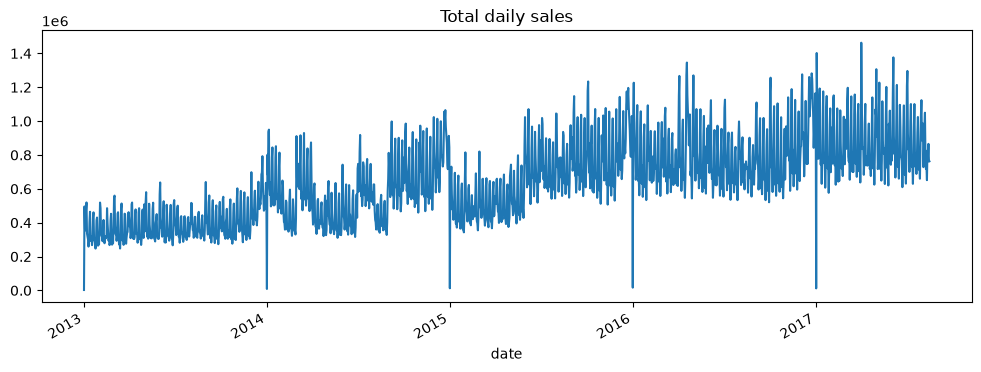

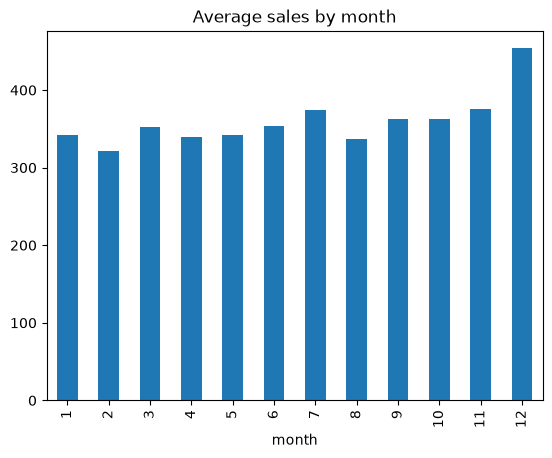

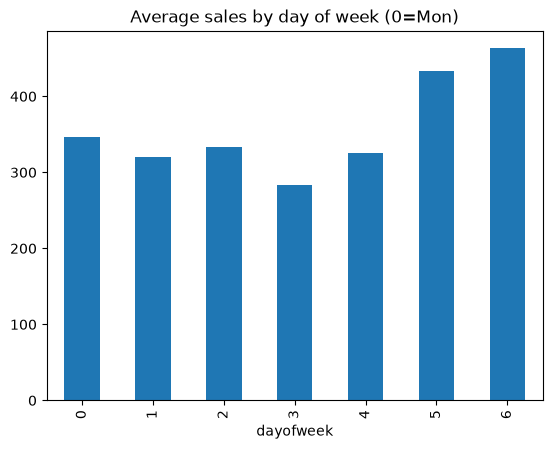

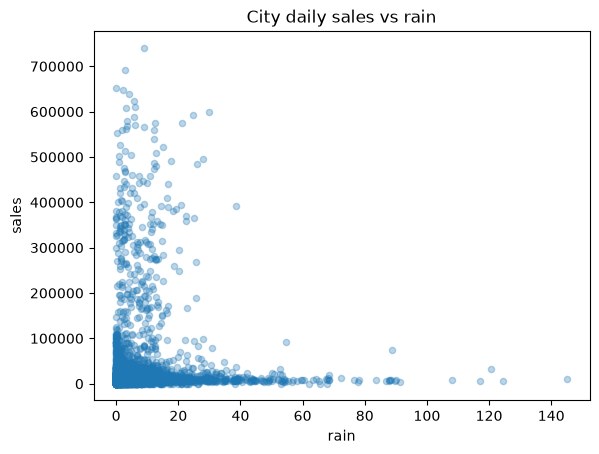

In [4]:
daily = df.groupby("date")["sales"].sum()
daily.plot(figsize=(12, 4), title="Total daily sales")
plt.show()

df.groupby("month")["sales"].mean().plot(kind="bar", title="Average sales by month")
plt.show()

df.groupby("dayofweek")["sales"].mean().plot(kind="bar", title="Average sales by day of week (0=Mon)")
plt.show()

city_day = df.groupby(["date", "city"], as_index=False).agg(
    sales=("sales", "sum"), rain=("precipitation_sum", "first"))
city_day.sample(5000, random_state=0).plot.scatter(x="rain", y="sales", alpha=0.3, title="City daily sales vs rain")
plt.show()

In [5]:
first_sale = df[df["sales"] > 0].groupby("store_nbr")["date"].min()
print(first_sale.sort_values().tail(15))   # stores whose first sale is late = opened later

store_nbr
15   2013-01-02
16   2013-01-02
17   2013-01-02
18   2013-01-02
19   2013-01-02
14   2013-01-02
54   2013-01-02
36   2013-05-09
53   2014-05-29
20   2015-02-13
29   2015-03-20
21   2015-07-24
42   2015-08-21
22   2015-10-09
52   2017-04-20
Name: date, dtype: datetime64[us]


In [6]:
   df = pd.read_csv("../Data/processed/merged.csv", parse_dates=["date"])
   print(df.shape, df.isna().sum().sum())
   first = df[df["sales"] > 0].groupby("store_nbr")["date"].min()
   print((df.groupby("store_nbr")["date"].min() == first).all())   
   print(df["family"].nunique(), (df["sales"] == 0).mean())        

(2778831, 28) 0
True
33 0.2580484383541137


In [7]:
a = pd.read_csv("../Data/raw/weather/Salinas.csv", parse_dates=["date"])
b = pd.read_csv("../Data/raw/weather/Libertad.csv", parse_dates=["date"])
same = (a["temperature_2m_mean"] == b["temperature_2m_mean"]).mean()
print(f"Share of days with identical mean temperature: {same:.1%}")
print(a["precipitation_sum"].corr(b["precipitation_sum"]))

Share of days with identical mean temperature: 6.8%
1.0


In [8]:
import glob
rain = pd.concat([pd.read_csv(f, parse_dates=["date"]) for f in glob.glob("../Data/raw/weather/*.csv")]) \
         .pivot(index="date", columns="city", values="precipitation_sum")
corr = rain.corr()
pairs = corr.where(corr.values > 0.999).stack()
print(pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)])
print("distinct rainfall series:", rain.T.drop_duplicates().shape[0])

city      city         
Ambato    Babahoyo        NaN
          Cayambe         NaN
          Cuenca          NaN
          Daule           NaN
          El Carmen       NaN
                           ..
Quito     Salinas         NaN
          Santo Domingo   NaN
Riobamba  Salinas         NaN
          Santo Domingo   NaN
Salinas   Santo Domingo   NaN
Length: 231, dtype: float64
distinct rainfall series: 21
